# 02 – Kết quả mô hình (Sleep DSS)

Notebook này **chỉ đọc và kiểm tra** kết quả do `src/train.py` tạo ra. Nó **không lưu** `models/model.joblib`, nên bấm Run All không làm mất mô hình chính thức.

- Nguồn duy nhất của quy trình huấn luyện: `python src/train.py` (ghi `model.joblib` và các file CSV trong `models/`).
- Cột đặc trưng, nhãn và cách chia train/test lấy từ `src/preprocess.py`, không định nghĩa lại ở đây.
- Muốn huấn luyện lại ngay trong notebook: đặt `RETRAIN = True` ở cell đầu (việc này **ghi đè** `models/model.joblib`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent                      # notebook nằm trong notebooks/
sys.path.insert(0, str(ROOT))

import joblib
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline

from src.preprocess import FEATURES, prepare_data

MODELS = ROOT / "models"
FIGURES = ROOT / "reports" / "figures"
RETRAIN = False   # True = chạy lại src/train.py và GHI ĐÈ models/model.joblib

In [2]:
if RETRAIN:
    from src.train import train_and_evaluate
    train_and_evaluate()
else:
    print("Bỏ qua huấn luyện: đang đọc kết quả đã có trong models/.")

Bỏ qua huấn luyện: đang đọc kết quả đã có trong models/.


In [3]:
# Cross-validation 5-fold trên tập huấn luyện: trung bình và độ lệch chuẩn
cv = pd.read_csv(MODELS / "cv_metrics.csv")
cv.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Most frequent,0.6010,0.0004,0.6010,0.0004,1.0000,0.0000,0.7508,0.0003,0.5000,0.0000
1,Logistic Regression,0.8628,0.0043,0.9093,0.0063,0.8574,0.0079,0.8825,0.0039,0.9408,0.0060
2,Random Forest,0.8601,0.0074,0.8915,0.0081,0.8737,0.0076,0.8825,0.0062,0.9356,0.0055
3,XGBoost,0.8676,0.0058,0.8960,0.0084,0.8823,0.0081,0.8891,0.0047,0.9407,0.0056


In [4]:
# Điểm trên tập kiểm tra (baseline + 3 mô hình)
metrics = pd.read_csv(MODELS / "metrics.csv")
metrics.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Most frequent,0.6012,0.6012,1.0000,0.7509,0.5000
1,Logistic Regression,0.8547,0.8983,0.8552,0.8762,0.9365
2,Random Forest,0.8565,0.8851,0.8748,0.8799,0.9312
3,XGBoost,0.8612,0.8907,0.8767,0.8836,0.9380


In [5]:
# Confusion matrix (tn, fp, fn, tp) từng mô hình
pd.read_csv(MODELS / "confusion_matrices.csv")

,model,tn,fp,fn,tp
0,Most frequent,0,678,0,1022
1,Logistic Regression,579,99,148,874
2,Random Forest,562,116,128,894
3,XGBoost,568,110,126,896


In [6]:
# Thí nghiệm rò rỉ dữ liệu: bản đúng (False) so với bản có cột kết quả giấc ngủ (True)
pd.read_csv(MODELS / "leakage_comparison.csv").round(4)

,include_leakage,model,accuracy,precision,recall,f1,roc_auc
0,False,Logistic Regression,0.8547,0.8983,0.8552,0.8762,0.9365
1,True,Logistic Regression,0.9841,0.9960,0.9775,0.9867,0.9997


,feature,importance
0,chronotype,1.8850
1,bedtime_phone_minutes,1.8435
2,occupation_type_Healthcare / Shift Worker,0.6811
3,occupation_type_Corporate 9-to-5,0.5265
4,occupation_type_Student,0.3668
5,occupation_type_Remote Tech,0.3460
6,gender_Male,0.2473
7,occupation_type_Freelance / Creative,0.2400
8,gender_Female,0.1803
9,caffeine_post_5pm_mg,0.0809


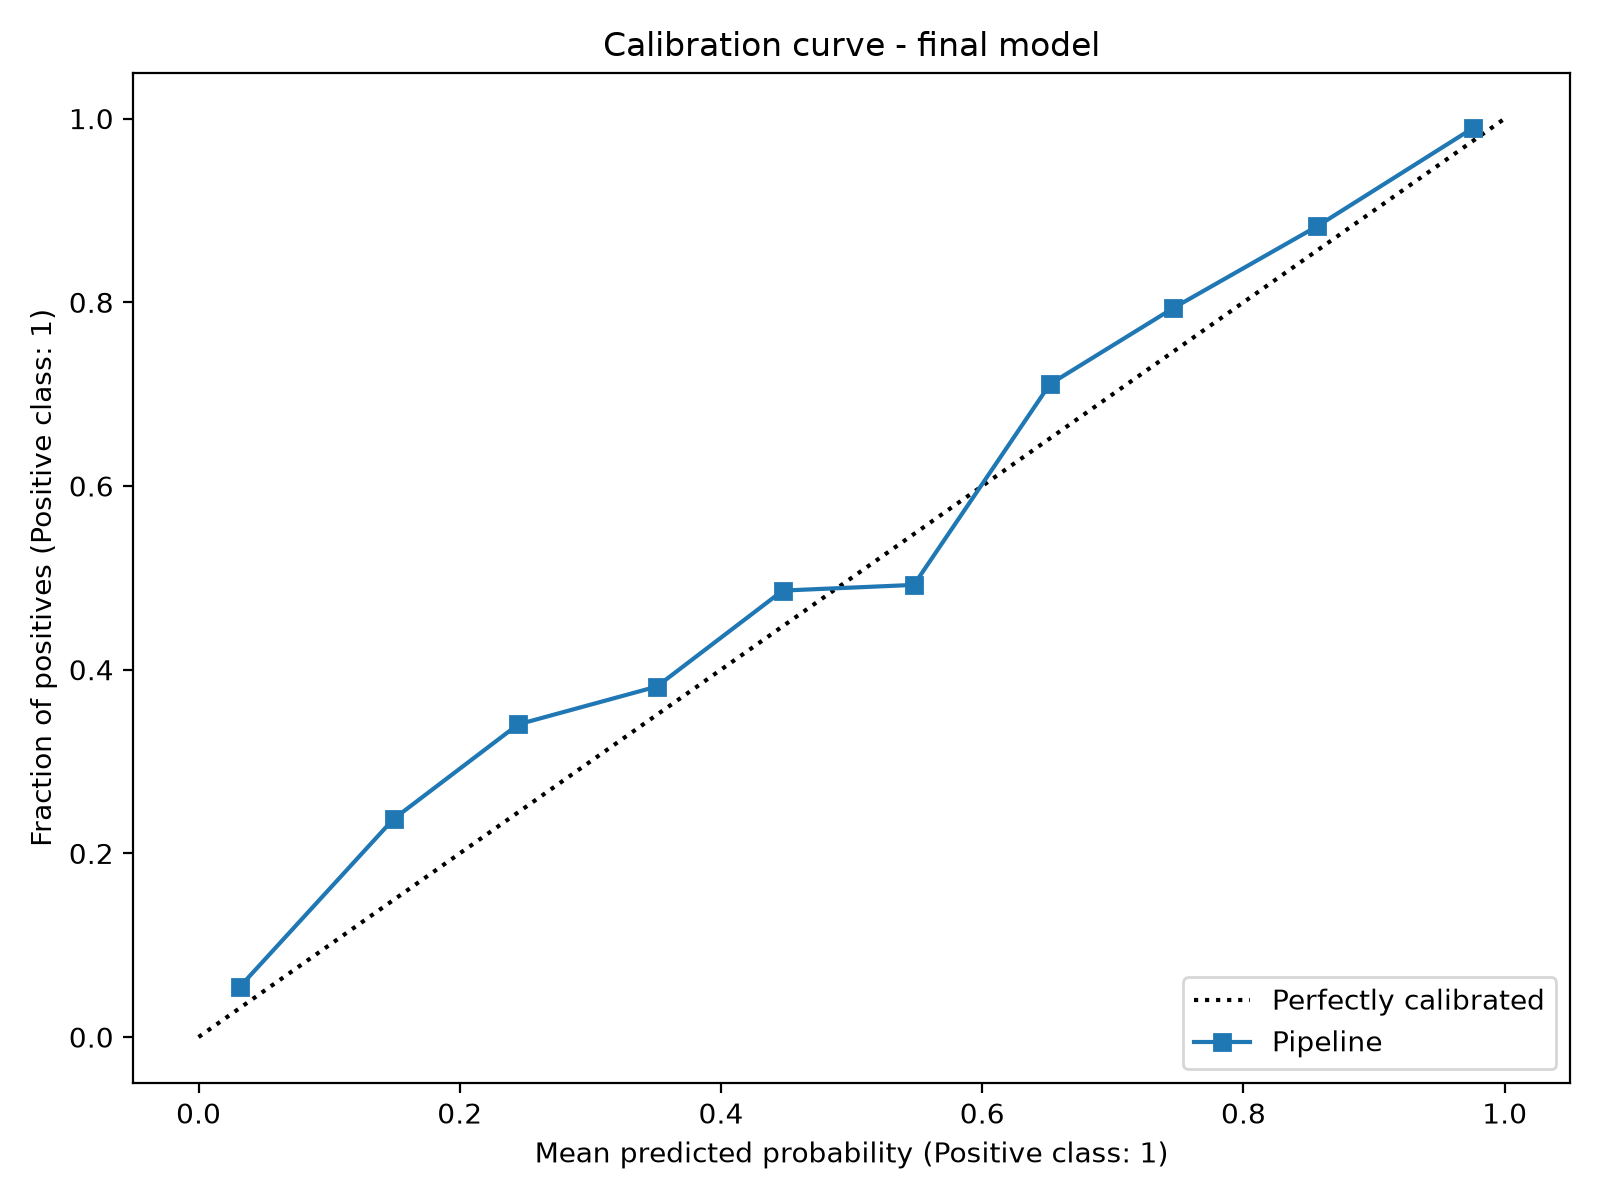

In [7]:
# Mức quan trọng của đặc trưng (tính trên đặc trưng sau mã hóa) và calibration
display(pd.read_csv(MODELS / "feature_importance.csv").head(10).round(4))
calib = FIGURES / "calibration_curve.png"
if calib.exists():
    display(Image(filename=calib))

In [8]:
# Kiểm tra model chính thức bằng cách chỉ ĐỌC: nạp, dự đoán, so với metrics.csv
model = joblib.load(MODELS / "model.joblib")
assert isinstance(model, Pipeline), "model.joblib phải là một Pipeline duy nhất"
print("Các bước:", [name for name, _ in model.steps], "| mô hình:", type(model[-1]).__name__)

# Mô hình được chọn theo ROC-AUC CV cao nhất (loại baseline), giống src/train.py
cv_auc = cv.set_index("model")["roc_auc_mean"].drop("Most frequent")
selected = cv_auc.idxmax()

_, X_test, _, y_test = prepare_data(random_state=42)
assert list(X_test.columns) == FEATURES
proba = model.predict_proba(X_test)[:, 1]
assert ((proba >= 0) & (proba <= 1)).all()

auc_now = roc_auc_score(y_test, proba)
auc_saved = metrics.set_index("model").loc[selected, "roc_auc"]
print(f"Mô hình được chọn theo CV: {selected}")
print(f"ROC-AUC tính lại: {auc_now:.4f} | trong metrics.csv: {auc_saved:.4f}")
assert abs(auc_now - auc_saved) < 1e-6, "model.joblib không khớp metrics.csv, hãy chạy lại python src/train.py"
print("Khớp. 5 xác suất đầu:", proba[:5].round(3))

Các bước: ['prep', 'model'] | mô hình: LogisticRegression
Mô hình được chọn theo CV: Logistic Regression
ROC-AUC tính lại: 0.9365 | trong metrics.csv: 0.9365
Khớp. 5 xác suất đầu: [0.212 0.037 0.012 0.28  0.051]
